# Midterm project, Group 9 topic
**Java vulnerability detection with CodeBERT and class-weighted cross-entropy**

MSITM 5134 Management of Organizational Data, KBTU. Bekzat Saulebay (25MD0294), individual work on the Group 9 topic.

This notebook goes through the project in the order of the lectures. It imports the same `.py` files that are in the folder, so the notebook and the scripts cannot drift apart. The data steps, the baselines, the evaluation and the demo run here for real. Training takes about three hours on my laptop, so by default the notebook reads the saved training runs from `runs/`. Set `RUN_TRAINING = True` to train again.

In [1]:
import json
import sqlite3

import pandas as pd
from IPython.display import Image, display
from transformers import AutoTokenizer

import alternative
import baselines
import common
import data_pipeline as dp
import demo
import evaluate
import train
from common import BASE, CONFIG, OUT, RUNS, WAREHOUSE, connect, hub_kwargs, sha256_of

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
RUN_TRAINING = False
print("device:", common.device())

/private/tmp/claude-501/-Users-s-Desktop-KBTU-Data-Org/b1b4a3a3-d104-4fab-8568-7ef7ee8329cf/scratchpad/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1027 14:53:13.239000 16174 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps


## 1. Data lifecycle and information value chain (Lecture 1)
The lifecycle uses the stages named in the task. Evaluation feeds back into validation: the leakage rule R5 exists because an earlier evaluation scored code it had already seen.

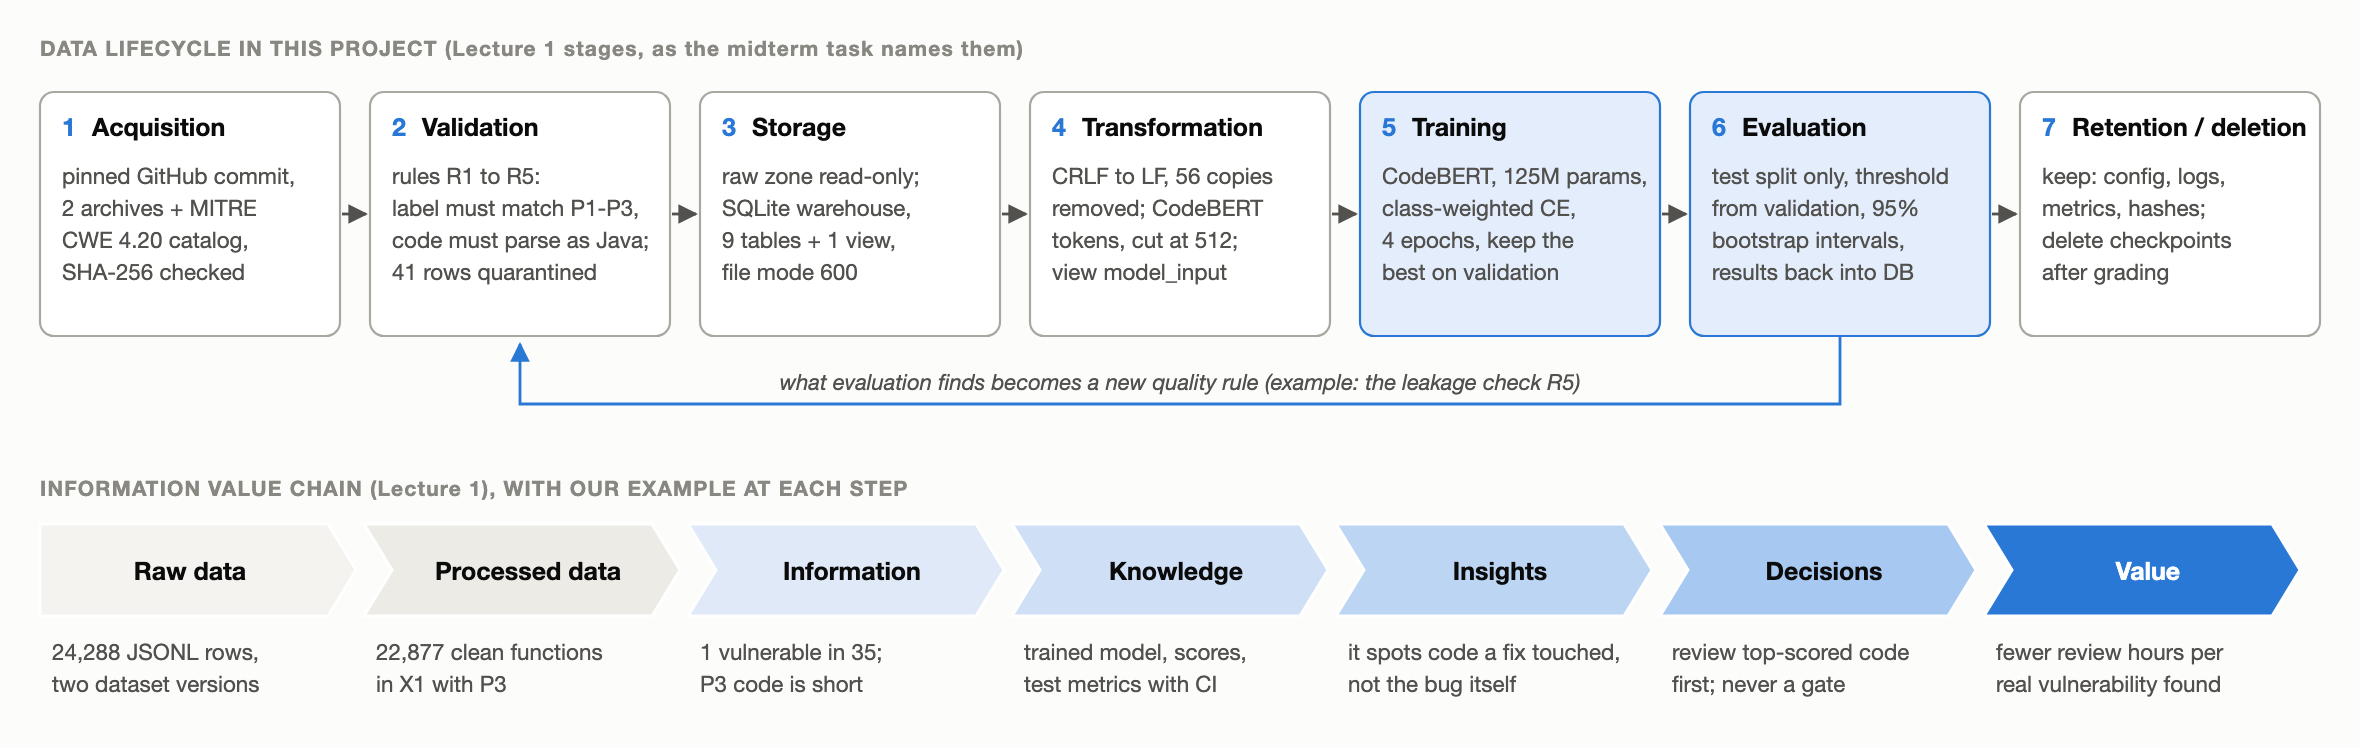

In [2]:
display(Image("diagrams/lifecycle.png", width=1000))

## 2. Governance: what I pinned and where the data comes from (Lecture 2)
Every source is fixed to an exact version in `config.json`. The roles (RACI) and the usage policy are in section 3 of the report.

In [3]:
print(json.dumps({k: CONFIG[k] for k in ["data", "model"]}, indent=2))

{
  "data": {
    "repository": "rmusab/vul-llm-finetune",
    "commit": "862ed17bd935aa86e1e1e95966fa84ecdaa88888",
    "archives": {
      "with_p3": {
        "path": "Datasets/with_p3/java_k_1_strict_2023_06_30.tar.gz",
        "sha256": "76e1bc8dd360d122b8939569bf57919df4f388d37d3f1762b0088732ba919e58"
      },
      "without_p3": {
        "path": "Datasets/without_p3/java_k_1_strict_2023_07_03.tar.gz",
        "sha256": "660e3d1d9b60248ab597d8465878330db83d028a8974ca99164671451ab1aba1"
      }
    },
    "cwe_catalog": {
      "version": "4.20",
      "url": "https://cwe.mitre.org/data/xml/cwec_v4.20.xml.zip",
      "sha256": "3976f599e5e5200219a3108bb896d06e2a88fbb293369e1883cb423a5e9d7d50"
    }
  },
  "model": {
    "name": "microsoft/codebert-base",
    "revision": "3b0952feddeffad0063f274080e3c23d75e7eb39",
    "max_length": 512
  }
}


## 3. ETL: extract and transform (Lecture 4)
Acquisition checks each archive against its SHA-256 and makes the raw files read-only. Extraction keeps the source file and line of every row.

In [4]:
common.LOG.clear()
sources = dp.acquire()
raw = dp.extract()


STEP 1  ACQUISITION
with_p3     already on disk, checksum verified; raw files set to read-only
without_p3  already on disk, checksum verified; raw files set to read-only
CWE 4.20    already on disk, checksum verified; set to read-only

STEP 2  EXTRACT


split       train  valid  test
variant                       
with_p3     13247   5131  4576
without_p3    810    272   252


function_id unique: True


In [5]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model"]["name"], **hub_kwargs())
df, audit = dp.transform(raw, tokenizer)


STEP 3  TRANSFORM AND CLEAN
R1  Windows line endings: 659 rows, normalised to LF, row kept
R2  label, status or split not allowed or not consistent: 0 rows, quarantined


R3  code is empty or does not parse as a Java method: 0 rows, quarantined
R4  same function has another label in the other dataset version: 38 rows, quarantined
R4  identical code carries both labels: 3 rows, quarantined
R5  copy of a function that is already in an earlier split (leakage): 33 rows, removed from the later split
R5  copy repeated inside the same split: 23 rows, removed, first copy kept



with_p3     22954 in, 22877 clean, 22 quarantined, 55 duplicates removed
without_p3  1334 in, 1314 clean, 19 quarantined, 1 duplicates removed


## 4. Data quality (Lecture 5)
The same quality dimensions before and after cleaning, the class distribution per split, and the length of the code in CodeBERT tokens.

In [6]:
quality, balance, lengths, issues = dp.assess(raw, df, audit)


STEP 4  DATA QUALITY ASSESSMENT
                                   with_p3           without_p3         
                                    before     after     before    after
rows                              22954.00  22877.00    1334.00  1314.00
completeness %                      100.00    100.00     100.00   100.00
uniqueness %                         99.52    100.00      99.85   100.00
validity %                          100.00    100.00     100.00   100.00
label consistency %                  99.90    100.00      98.58   100.00
functions in more than one split     29.00      0.00       1.00     0.00
rows with CRLF line endings         624.00      0.00      35.00     0.00
positives                           646.00    644.00     665.00   645.00
negatives                         22308.00  22233.00     669.00   669.00
prevalence %                          2.81      2.82      49.85    49.09
negatives per positive               34.50     34.50       1.00     1.00

Class distributio

In [7]:
display(issues)

,rule,reason,action,rows
0,R1,Windows line endings,"normalised to LF, row kept",659
1,R4,identical code carries both labels,quarantined,3
2,R4,same function has another label in the other d...,quarantined,38
3,R5,copy of a function that is already in an earli...,removed from the later split,33
4,R5,copy repeated inside the same split,"removed, first copy kept",23


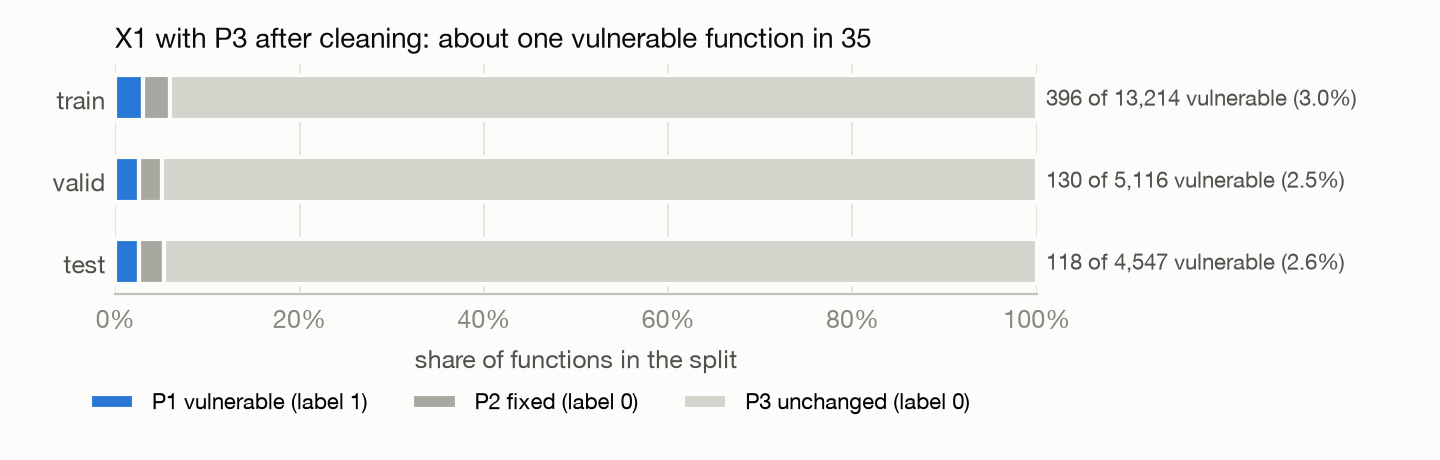

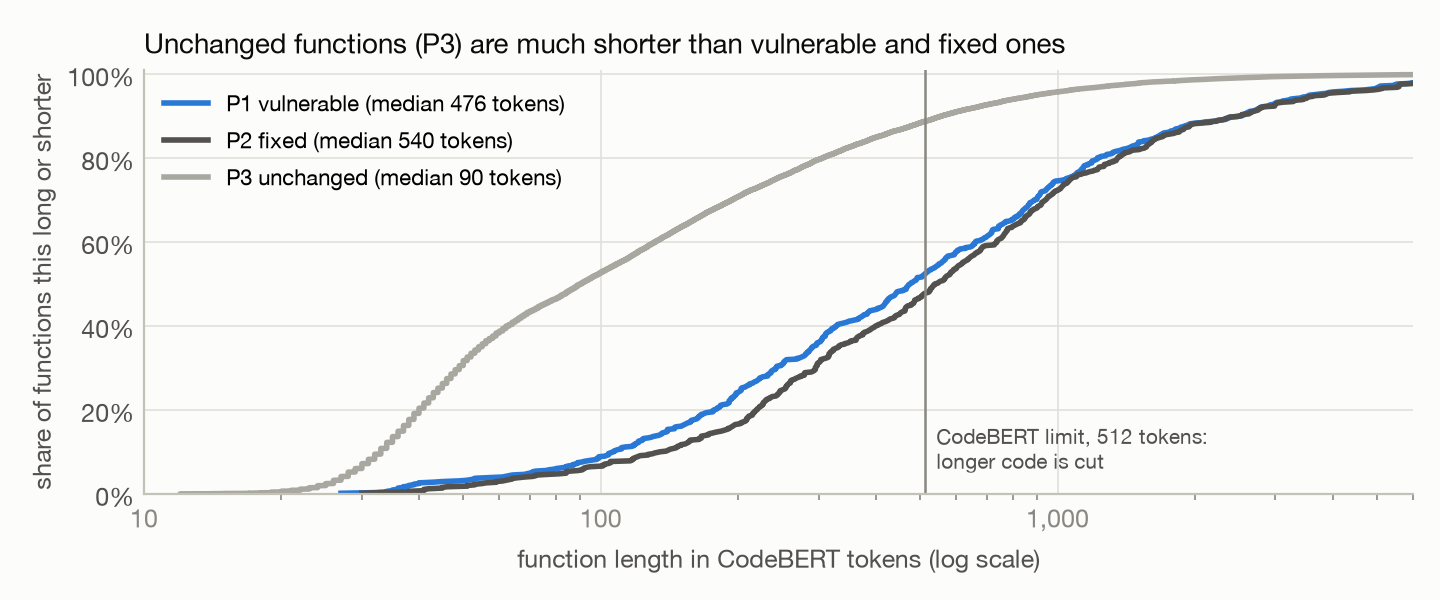

In [8]:
dp.draw_balance(balance)
dp.draw_lengths(df)
display(Image(OUT / "fig_class_balance.png", width=900))
display(Image(OUT / "fig_token_lengths.png", width=900))

## 5. Load into the warehouse and the data model (Lectures 3 and 4)
The warehouse tables are the entities of the ER model. Training reads the view `model_input`; evaluation writes `experiment_run`, `prediction` and `metric` back.


STEP 5  LOAD INTO THE WAREHOUSE


dataset_version        2
label_partition        3
cwe                 1452
vcs_commit           839
java_function      24288
quality_issue        756
experiment_run         0
prediction             0
metric                 0

model_input view (what training reads):
   variant split  rows  positives
   with_p3  test  4547        118
   with_p3 train 13214        396
   with_p3 valid  5116        130
without_p3  test   246        117
without_p3 train   801        394
without_p3 valid   267        134

warehouse file permissions set to owner read/write only (600)


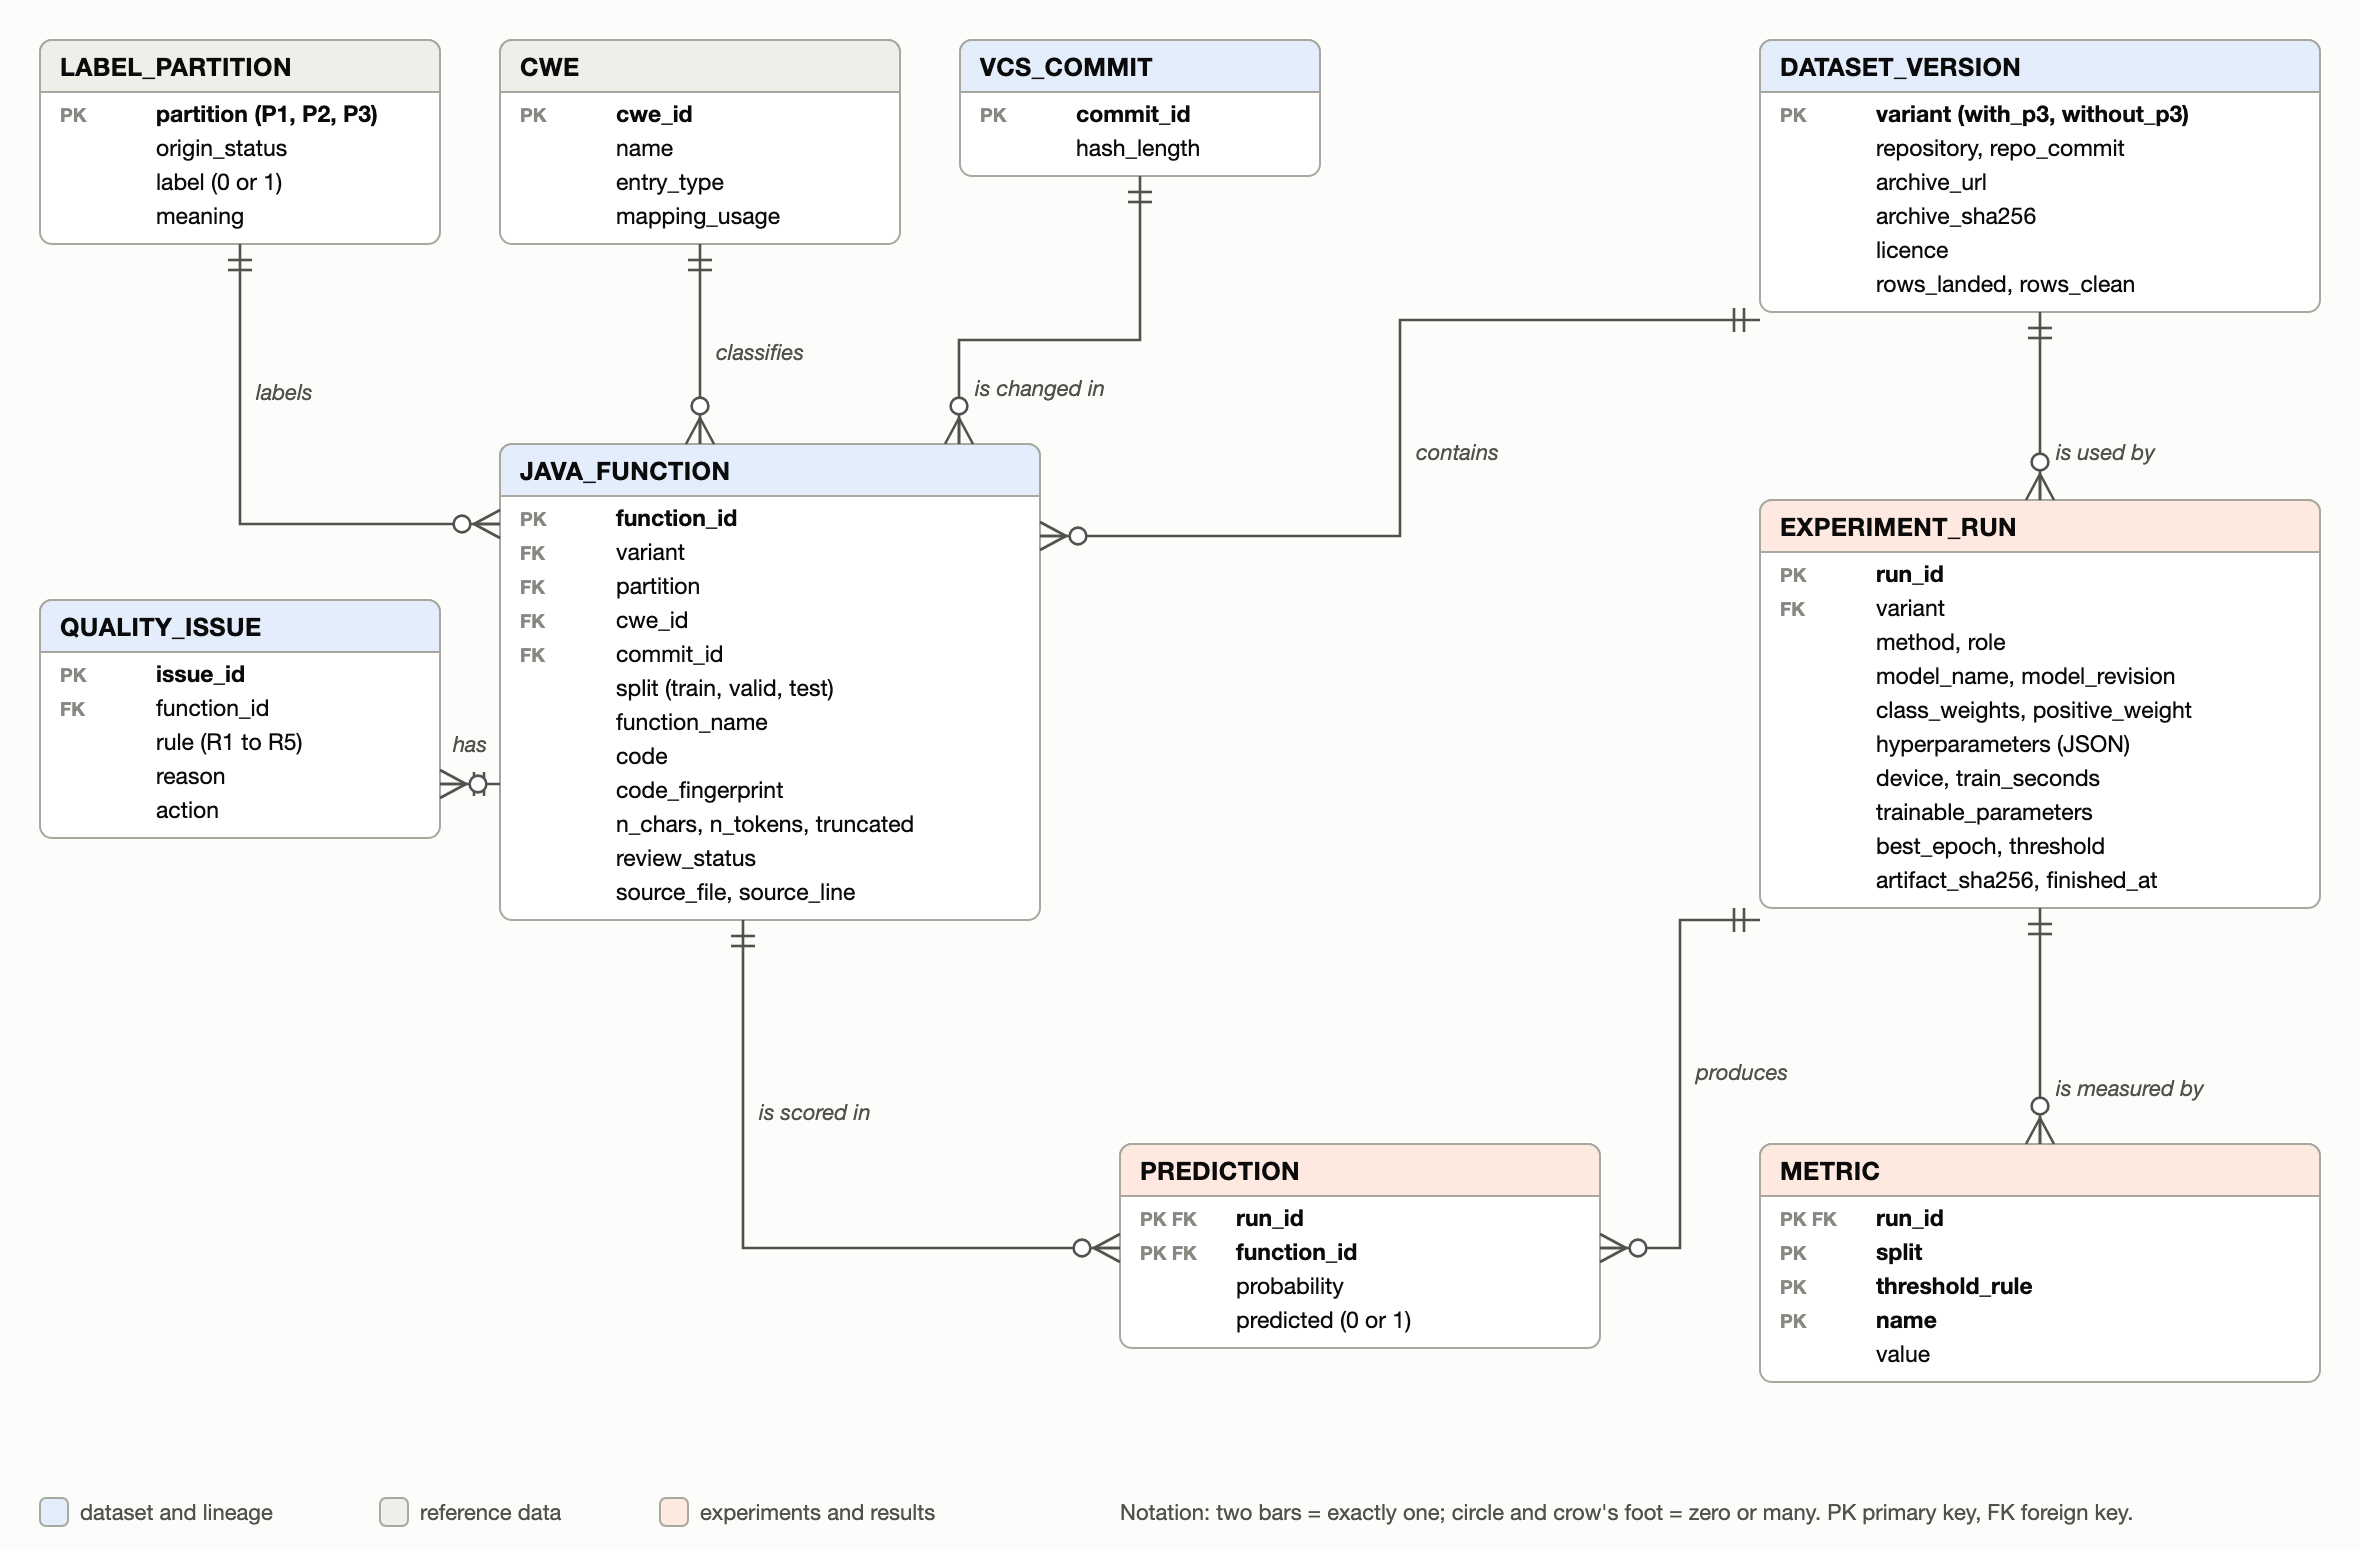

In [9]:
counts = dp.load(df, audit, sources)
dp.summarise(raw, df, audit, quality, balance, counts, sources)
common.save_log(OUT / "01_data_pipeline_log.txt")
display(Image("diagrams/er_model.png", width=1000))

In [10]:
con = connect(read_only=True)
print(con.execute("SELECT sql FROM sqlite_master WHERE name = 'model_input'").fetchone()[0])
display(pd.read_sql("SELECT p.partition, p.origin_status, p.label, COUNT(*) AS functions "
                    "FROM java_function f JOIN label_partition p ON p.partition = f.partition "
                    "WHERE f.variant = 'with_p3' AND f.review_status = 'clean' GROUP BY p.partition", con))
display(pd.read_sql("SELECT rule, reason, action, COUNT(*) AS rows FROM quality_issue GROUP BY rule, reason, action", con))
con.close()

CREATE VIEW model_input AS
SELECT f.function_id, f.variant, f.split, f.code, p.label, f.partition, f.cwe_id, f.n_tokens
FROM java_function f JOIN label_partition p ON p.partition = f.partition
WHERE f.review_status = 'clean'


,partition,origin_status,label,functions
0,P1,VULNERABLE,1,644
1,P2,FIXED,0,647
2,P3,NOT_VULNERABLE,0,21586


,rule,reason,action,rows
0,R1,Windows line endings,"normalised to LF, row kept",659
1,R4,identical code carries both labels,quarantined,3
2,R4,same function has another label in the other d...,quarantined,38
3,R5,copy of a function that is already in an earli...,removed from the later split,33
4,R5,copy repeated inside the same split,"removed, first copy kept",23


## 6. Security controls (Lecture 6)
Raw files are read-only, the warehouse is readable by its owner only, scripts that only read open the database in read-only mode, and every model file is checked against the SHA-256 written when it was trained.

In [11]:
for path in sorted(common.RAW.rglob("*")):
    if path.is_file():
        print(oct(path.stat().st_mode & 0o777), path.relative_to(BASE))
print(oct(WAREHOUSE.stat().st_mode & 0o777), WAREHOUSE.relative_to(BASE))

0o444 data/raw/cwec_v4.20.xml.zip
0o444 data/raw/with_p3/test.jsonl
0o444 data/raw/with_p3/train.jsonl
0o444 data/raw/with_p3/valid.jsonl
0o444 data/raw/with_p3.tar.gz
0o444 data/raw/without_p3/test.jsonl
0o444 data/raw/without_p3/train.jsonl
0o444 data/raw/without_p3/valid.jsonl
0o444 data/raw/without_p3.tar.gz
0o600 data/warehouse.db


In [12]:
con = connect(read_only=True)
try:
    con.execute("DELETE FROM java_function")
except sqlite3.OperationalError as error:
    print("write refused on the read-only connection:", error)
con.close()

write refused on the read-only connection: attempt to write a readonly database


In [13]:
for summary_file in sorted(RUNS.glob("*/run_summary.json")):
    summary = json.loads(summary_file.read_text())
    if summary.get("checkpoint_sha256"):
        artifact = BASE / summary["checkpoint"]
        artifact = artifact / "model.safetensors" if artifact.is_dir() else artifact
        status = "matches" if artifact.exists() and sha256_of(artifact) == summary["checkpoint_sha256"] else "MISSING OR CHANGED"
        print(f"{summary['run']:<32} {summary['checkpoint_sha256'][:16]}...  {status}")

codebert_plain                   a6ba33a5a36531b1...  matches


codebert_sqrt                    90ca7e1b6a5ad98f...  matches


codebert_weighted                fc78875053b782c3...  matches


codebert_weighted_balanced_set   5e99582106b3856f...  matches
frozen_codebert_lr               8f9b46f69810aee3...  matches


## 7. Training: primary method, ablations and the alternative
`config.json` is the model configuration. With `RUN_TRAINING = False` the cell below prints the saved logs instead of training.

In [14]:
print(json.dumps({k: CONFIG[k] for k in ["training", "runs", "alternative"]}, indent=2))
if RUN_TRAINING:
    for run_name in CONFIG["runs"]:
        train.train(run_name)
    alternative.main()

{
  "training": {
    "batch_size": 16,
    "eval_batch_size": 64,
    "learning_rate": 2e-05,
    "weight_decay": 0.01,
    "warmup_ratio": 0.1,
    "max_grad_norm": 1.0,
    "bucket_size": 50
  },
  "runs": {
    "codebert_weighted": {
      "role": "primary method",
      "variant": "with_p3",
      "class_weights": "balanced",
      "epochs": 4
    },
    "codebert_plain": {
      "role": "ablation, paper baseline without weights",
      "variant": "with_p3",
      "class_weights": "none",
      "epochs": 4
    },
    "codebert_sqrt": {
      "role": "ablation, milder weights",
      "variant": "with_p3",
      "class_weights": "sqrt",
      "epochs": 4
    },
    "codebert_weighted_balanced_set": {
      "role": "same method on the balanced dataset",
      "variant": "without_p3",
      "class_weights": "balanced",
      "epochs": 10
    }
  },
  "alternative": {
    "name": "frozen_codebert_lr",
    "role": "alternative method",
    "variant": "with_p3",
    "pooling": "mean",
  

In [15]:
for run_name in ["codebert_weighted", "codebert_plain", "codebert_sqrt", "codebert_weighted_balanced_set", "frozen_codebert_lr"]:
    if not (RUNS / run_name / "train.log").exists():
        print(f"{run_name}: not trained yet")
        continue
    log = (RUNS / run_name / "train.log").read_text().splitlines()
    print("\n".join(line for line in log if " step " not in line))
    print()

run codebert_weighted: primary method
variant with_p3, device mps, epochs 4, batch 16, lr 2e-05
train  13214 functions,  396 vulnerable
valid   5116 functions,  130 vulnerable
test    4547 functions,  118 vulnerable
class weights (balanced): not vulnerable 0.515, vulnerable 16.684
inputs cut at 512 tokens: 13.4%
trainable parameters 124,647,170; 826 steps per epoch, 3304 in total
epoch 1: train loss 0.7282, valid ROC AUC 0.8271, valid PR AUC 0.1076, 741s  -> best so far, checkpoint saved
epoch 2: train loss 0.6404, valid ROC AUC 0.8471, valid PR AUC 0.1253, 734s  -> best so far, checkpoint saved
epoch 3: train loss 0.5834, valid ROC AUC 0.8535, valid PR AUC 0.1340, 732s  -> best so far, checkpoint saved
epoch 4: train loss 0.5249, valid ROC AUC 0.8600, valid PR AUC 0.1494, 732s  -> best so far, checkpoint saved
best epoch 4 (valid ROC AUC 0.8600); total 49.0 min

run codebert_plain: ablation, paper baseline without weights
variant with_p3, device mps, epochs 4, batch 16, lr 2e-05
train

In [16]:
display(pd.concat({name: pd.read_csv(RUNS / name / "train_log.csv")
                   for name in ["codebert_weighted", "codebert_plain", "codebert_sqrt"]
                   if (RUNS / name / "train_log.csv").exists()}))

epoch  train_loss  valid_log_loss  valid_roc_auc  valid_pr_auc  learning_rate_end  train_seconds  epoch_seconds
codebert_weighted 0      1    0.728178        0.100587       0.827081      0.107602           0.000017          701.7          741.2
                  1      2    0.640430        0.153307       0.847056      0.125339           0.000011          694.5          733.5
                  2      3    0.583417        0.224311       0.853523      0.134042           0.000006          692.9          732.3
                  3      4    0.524917        0.151839       0.860041      0.149355           0.000000          693.2          732.1
codebert_plain    0      1    0.152557        0.099501       0.836565      0.113561           0.000017          682.5          721.0
                  1      2    0.119214        0.097793       0.868639      0.164365           0.000011          701.3          740.2
                  2      3    0.103247        0.103060       0.864293      0.153276           0.000006          677.0          715.0
                  3      4    0.085761        0.115888       0.872081      0.165790           0.000000          675.2          713.4
codebert_sqrt     0      1    0.408035        0.106390       0.832587      0.122834           0.000017          674.8          713.2
                  1      2    0.359597        0.130560       0.845611      0.133454           0.000011          674.1          712.1
                  2      3    0.337134        0.119031       0.847631      0.135672           0.000006          672.9          711.1
                  3      4    0.300167        0.113549       0.856041      0.145041           0.000000          675.6          715.0

## 8. Evaluation and visualization (Lecture 7)
The threshold for every model is the one with the best F1 on the validation split, as in the paper. All metrics below are on the test split, which no model saw during training or threshold choice.

In [17]:
common.LOG.clear()
baselines.main()
common.LOG.clear()
results = evaluate.main()


REFERENCE BASELINES
majority_with_p3         valid ROC AUC 0.5000  (0.0s)
length_lr_with_p3        valid ROC AUC 0.8133  (0.0s)


tfidf_lr_with_p3         valid ROC AUC 0.8516  (2.1s)
majority_without_p3      valid ROC AUC 0.5000  (0.0s)
length_lr_without_p3     valid ROC AUC 0.5417  (0.0s)


tfidf_lr_without_p3      valid ROC AUC 0.5524  (0.4s)
runs found: codebert_weighted, codebert_plain, codebert_sqrt, frozen_codebert_lr, tfidf_lr_with_p3, length_lr_with_p3, majority_with_p3, codebert_weighted_balanced_set, tfidf_lr_without_p3, length_lr_without_p3, majority_without_p3

STEP 1  TEST METRICS (threshold tuned on validation for the best F1)


                           run  accuracy  precision  recall     f1  roc_auc  roc_auc_low  roc_auc_high  pr_auc  roc_auc_p1_vs_p2  threshold  tp  fp  fn   tn
             codebert_weighted    0.9046     0.1409  0.5254 0.2222   0.8494       0.8161        0.8798  0.1555            0.4699     0.2137  62 378  56 4051
                codebert_plain    0.9281     0.1881  0.5339 0.2781   0.8625       0.8282        0.8938  0.1859            0.4846     0.0447  63 272  55 4157
                 codebert_sqrt    0.9213     0.1450  0.4153 0.2149   0.8512       0.8202        0.8802  0.1417            0.4728     0.1639  49 289  69 4140
            frozen_codebert_lr    0.8656     0.0912  0.4661 0.1526   0.8193       0.7837        0.8528  0.1159            0.4596     0.7391  55 548  63 3881
              tfidf_lr_with_p3    0.9554     0.2678  0.4153 0.3256   0.8714       0.8394        0.9007  0.2141            0.5051     0.6616  49 134  69 4295
             length_lr_with_p3    0.8995     0.1049  0.381

In [18]:
table = pd.read_csv(OUT / "02_metrics_test.csv")
columns = ["run", "accuracy", "precision", "recall", "f1", "roc_auc", "roc_auc_low", "roc_auc_high", "pr_auc",
           "roc_auc_p1_vs_p2", "meets_accuracy_target"]
display(table[columns].round(3))

,run,accuracy,precision,recall,f1,roc_auc,roc_auc_low,roc_auc_high,pr_auc,roc_auc_p1_vs_p2,meets_accuracy_target
0,codebert_weighted,0.905,0.141,0.525,0.222,0.849,0.816,0.880,0.156,0.470,False
1,codebert_plain,0.928,0.188,0.534,0.278,0.862,0.828,0.894,0.186,0.485,False
2,codebert_sqrt,0.921,0.145,0.415,0.215,0.851,0.820,0.880,0.142,0.473,False
3,frozen_codebert_lr,0.866,0.091,0.466,0.153,0.819,0.784,0.853,0.116,0.460,False
4,tfidf_lr_with_p3,0.955,0.268,0.415,0.326,0.871,0.839,0.901,0.214,0.505,True
5,length_lr_with_p3,0.899,0.105,0.381,0.165,0.807,0.772,0.841,0.135,0.470,False
6,majority_with_p3,0.974,0.000,0.000,0.000,0.500,0.500,0.500,0.026,0.500,True
7,codebert_weighted_balanced_set,0.500,0.487,0.940,0.641,0.560,0.490,0.634,0.550,0.560,False
8,tfidf_lr_without_p3,0.480,0.477,0.974,0.640,0.598,0.523,0.670,0.597,0.598,False
9,length_lr_without_p3,0.476,0.476,1.000,0.645,0.536,0.464,0.609,0.530,0.536,False


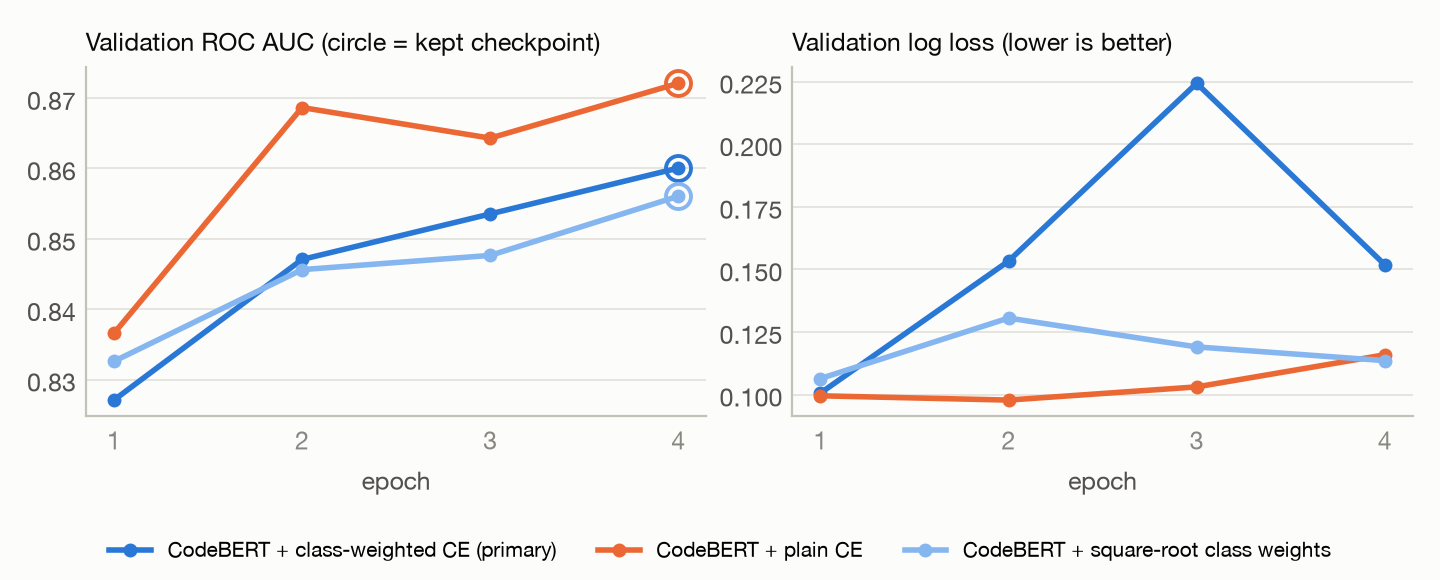

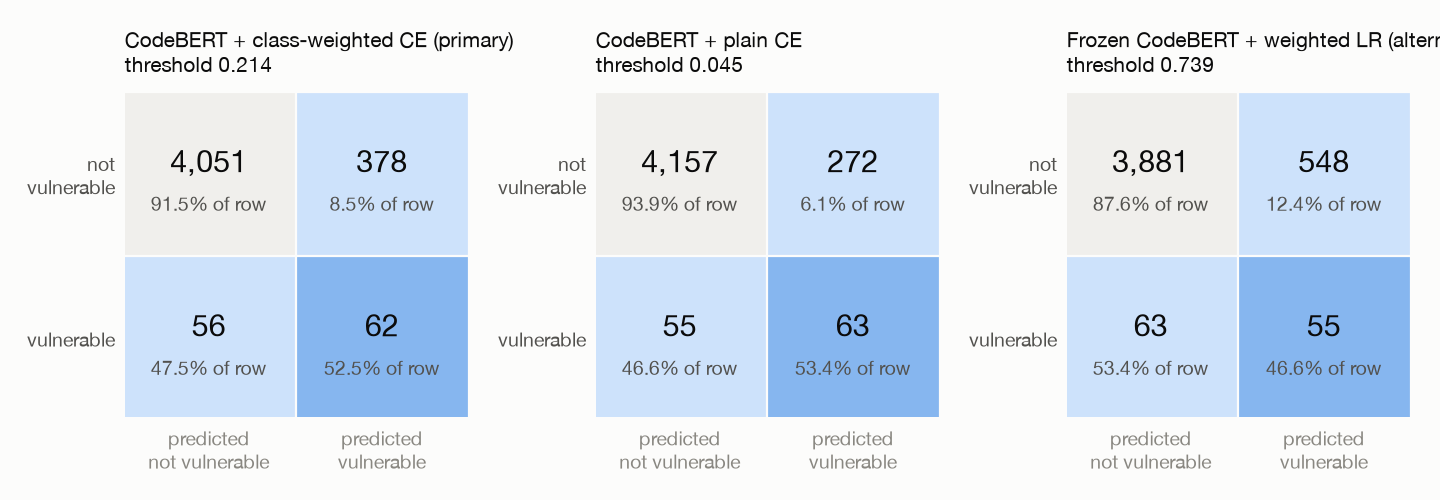

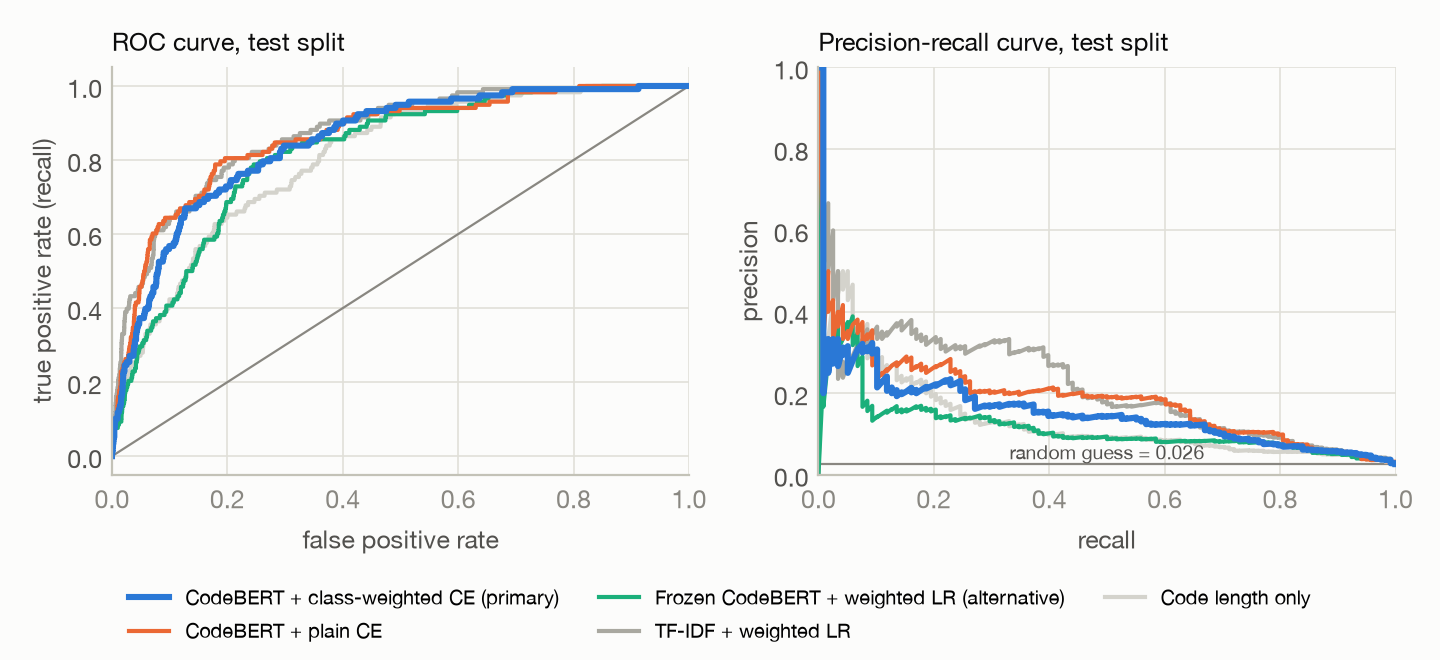

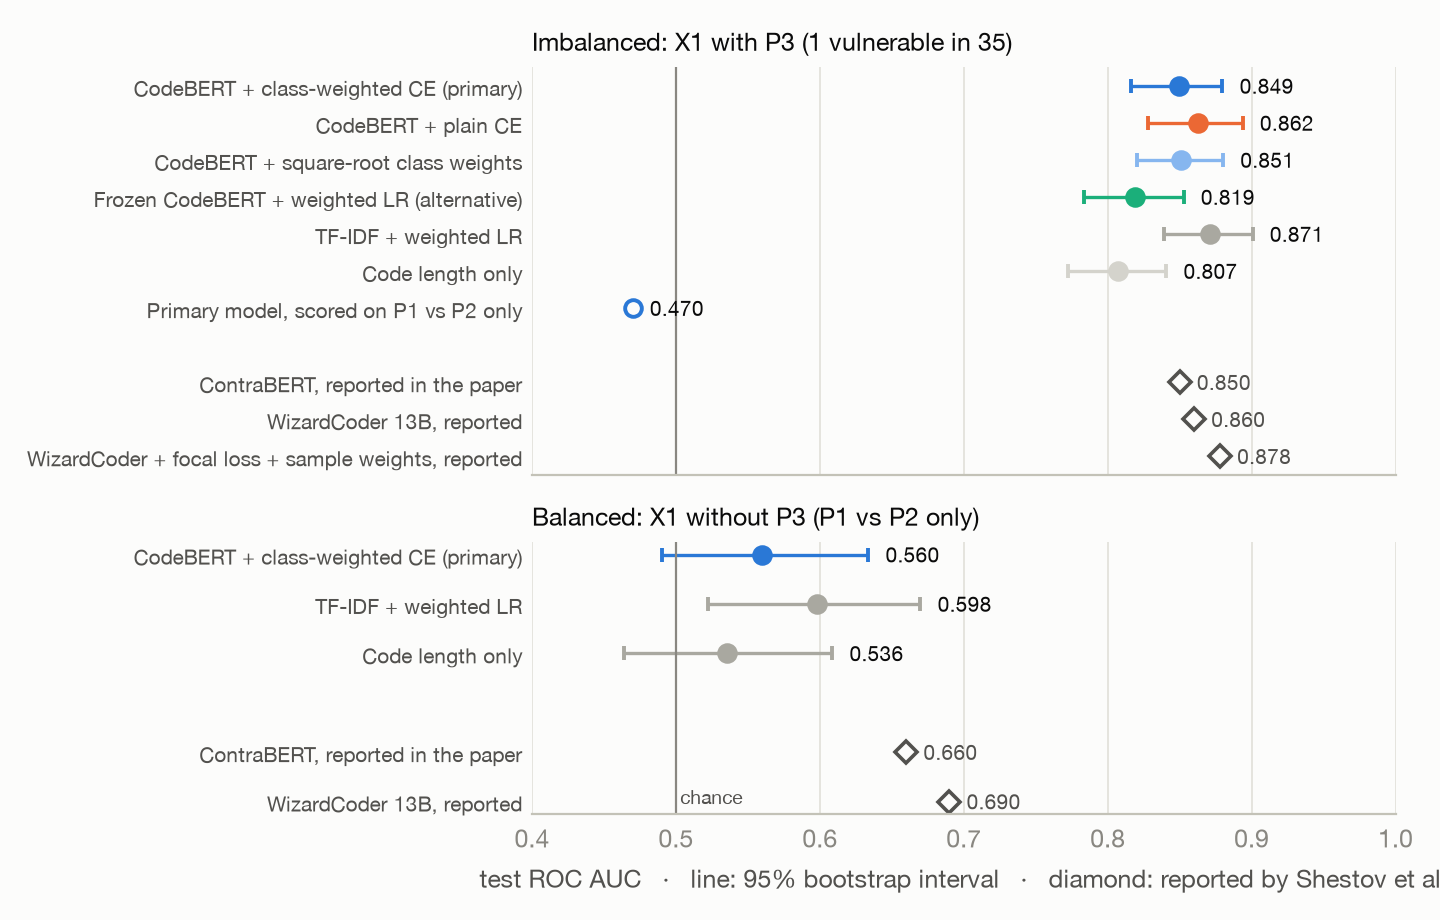

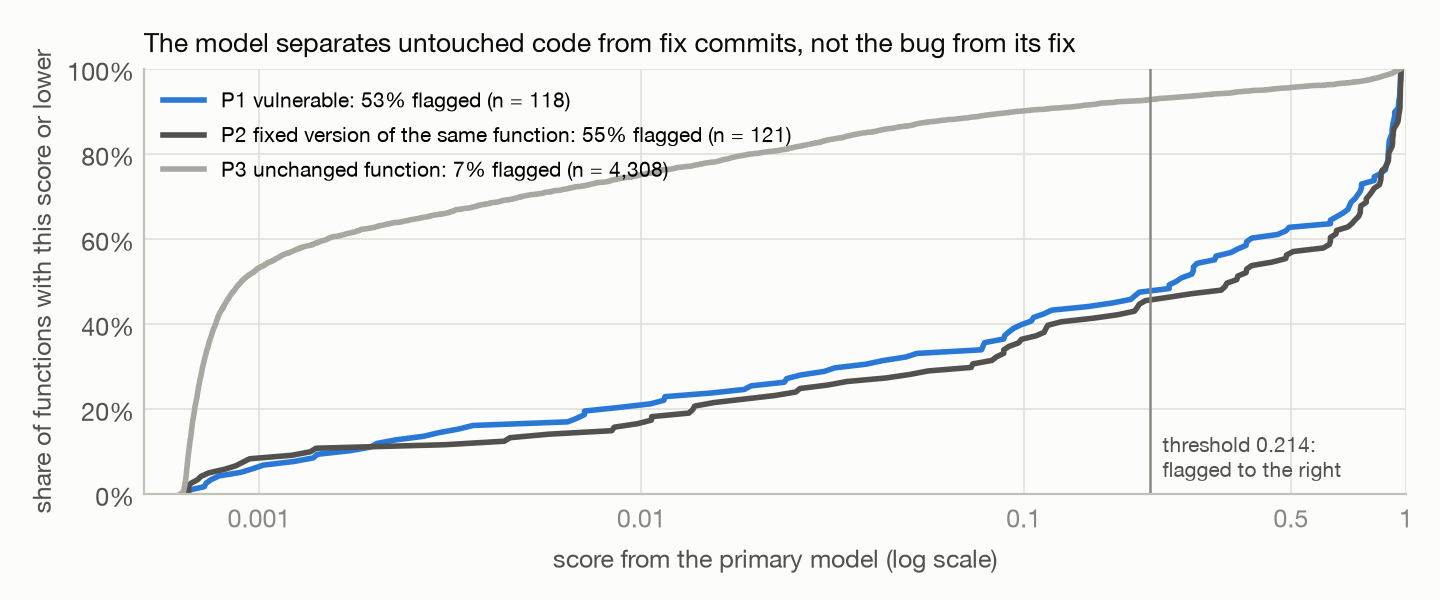

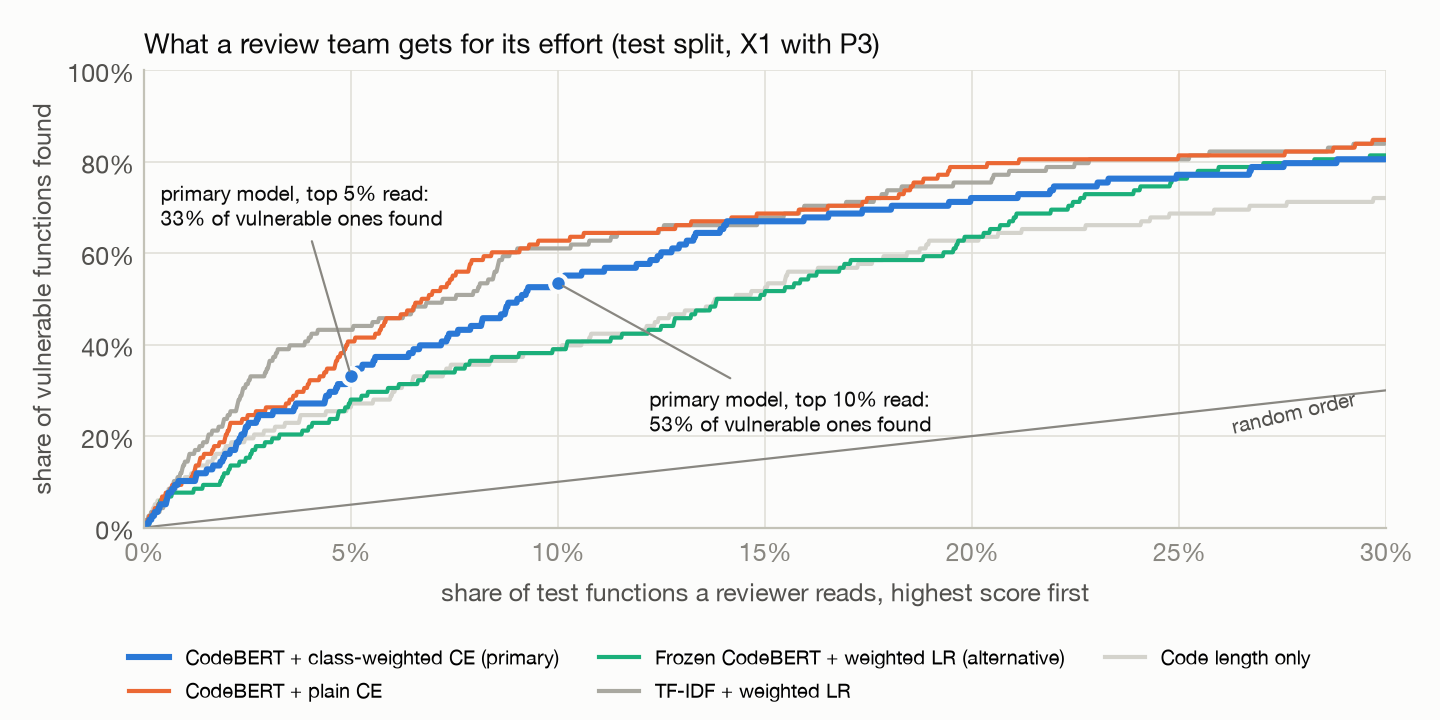

,run,rule,threshold,accuracy,recall,flagged,meets_accuracy_target
0,codebert_weighted,best F1 on validation,0.214,0.905,0.525,440,False
1,codebert_weighted,accuracy 93% on validation,0.232,0.907,0.525,427,False
2,codebert_weighted,default 0.5,0.500,0.931,0.373,286,True
3,codebert_plain,best F1 on validation,0.045,0.928,0.534,335,False
4,codebert_plain,accuracy 93% on validation,0.032,0.919,0.602,391,False
5,codebert_plain,default 0.5,0.500,0.974,0.025,8,True
6,codebert_sqrt,best F1 on validation,0.164,0.921,0.415,338,False
7,codebert_sqrt,accuracy 93% on validation,0.063,0.903,0.534,448,False
8,codebert_sqrt,default 0.5,0.500,0.956,0.220,134,True
9,frozen_codebert_lr,best F1 on validation,0.739,0.866,0.466,603,False


In [19]:
for name in ["fig_training_curves", "fig_confusion", "fig_roc_pr", "fig_method_comparison", "fig_partition_scores", "fig_review_budget"]:
    display(Image(OUT / f"{name}.png", width=900))
display(pd.read_csv(OUT / "02_operating_points.csv")[["run", "rule", "threshold", "accuracy", "recall", "flagged", "meets_accuracy_target"]].round(3))

## 9. Live demo
The demo checks the checkpoint hash before loading, then scores three hand-written methods and two real test functions from each partition.

In [20]:
tokenizer, model, threshold, digest = demo.load("codebert_weighted")
print(f"checkpoint {digest[:16]}... verified, threshold {threshold:.3f}")
for name, source in demo.EXAMPLES.items():
    print(f"{name:<28} score {demo.score(tokenizer, model, source):.3f}")
sample = demo.test_sample(2)
sample["score"] = [demo.score(tokenizer, model, source) for source in sample["code"]]
display(sample[["function_id", "function_name", "cwe_id", "partition", "label", "score"]].round(3))

checkpoint fc78875053b782c3... verified, threshold 0.214


login, SQL built by hand     score 0.002
login, prepared statement    score 0.003
simple getter                score 0.001


,function_id,function_name,cwe_id,partition,label,score
3628,with_p3/49000,deactivate,CWE-362,P1,1,0.275
2249,with_p3/80641,setUp,CWE-79,P1,1,0.963
3509,with_p3/6240,readObject,CWE-20,P2,0,0.014
607,with_p3/83018,parse,CWE-835,P2,0,0.885
2643,with_p3/54006,isSPLenient,CWE-444,P3,0,0.001
2785,with_p3/6236,getIdTokenString,CWE-20,P3,0,0.001
